# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\tatev\Downloads\task4\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        Xb = self._add_bias(X)
        N = Xb.shape[0]
        if self.w0 is None:
            self.w = np.zeros(Xb.shape[1])
        else:
            self.w = np.asarray(self.w0, dtype=float).copy()

        self.n_iter_ = 0
        for _ in range(self.max_iter):
            # loss на всей обучающей выборке до шага
            self.loss_history.append(self.calc_loss(Xb, y))

            if self.gd_type == 'full':
                grad = self.calc_gradient(Xb, y)
            elif self.gd_type == 'stochastic':
                idx = rng.choice(N, size=min(self.batch_size, N), replace=False)
                grad = self.calc_gradient(Xb[idx], y[idx])
            else:
                raise ValueError("gd_type должен быть 'full' или 'stochastic'")

            w_new = self.w - self.eta * grad
            diff = np.linalg.norm(w_new - self.w)
            self.w = w_new
            self.n_iter_ += 1
            if diff < self.tolerance:
                break

        return self

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)  # защита от переполнения в exp
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        Xb = self._add_bias(np.asarray(X, dtype=float))
        p1 = self.sigmoid(Xb @ self.w)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        eps = 1e-15
        p = np.clip(self.sigmoid(X @ self.w), eps, 1 - eps)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD: итераций = 1000, остановка по max_iter, финальный loss = 0.5125
SGD: итераций = 1000, остановка по max_iter, финальный loss = 0.5129


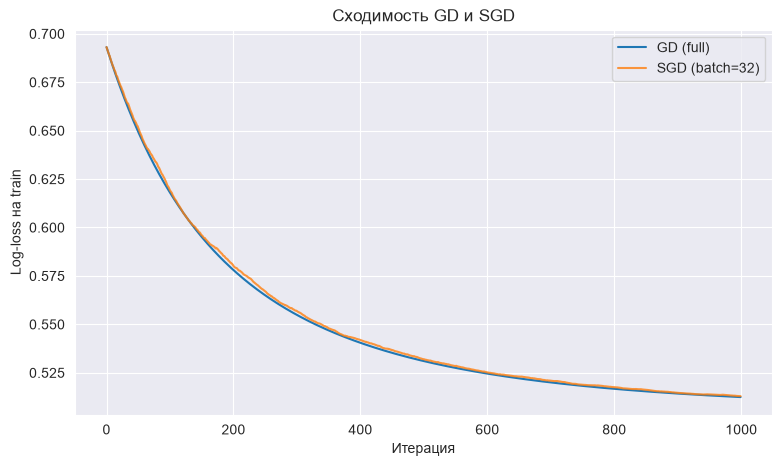

In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

for name, m in [('GD', gd), ('SGD', sgd)]:
    stop = 'max_iter' if m.n_iter_ == m.max_iter else 'tolerance'
    print(f'{name}: итераций = {m.n_iter_}, остановка по {stop}, финальный loss = {m.loss_history[-1]:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(gd.loss_history, label='GD (full)')
plt.plot(sgd.loss_history, label='SGD (batch=32)', alpha=0.8)
plt.xlabel('Итерация')
plt.ylabel('Log-loss на train')
plt.title('Сходимость GD и SGD')
plt.legend()
plt.show()

**Выводы.**
- Обе модели остановились по `max_iter` (1000 итераций). GD при `eta=0.01` просто ещё не успел сойтись, а SGD до `tolerance` не дойдёт никогда.
- У SGD градиент считается по случайному батчу, поэтому он шумный: даже рядом с минимумом шаг $\eta \cdot \nabla$ не становится маленьким, веса «дрожат», и разность весов не падает ниже `tolerance`. Чтобы SGD остановился, шаг нужно уменьшать со временем.
- График GD гладкий и монотонно убывает, у SGD он идёт примерно так же, но с шумом (небольшие скачки вверх-вниз).
- GD за итерацию просматривает все $N = 14000$ объектов обучающей выборки, SGD — только `batch_size = 32` объекта.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

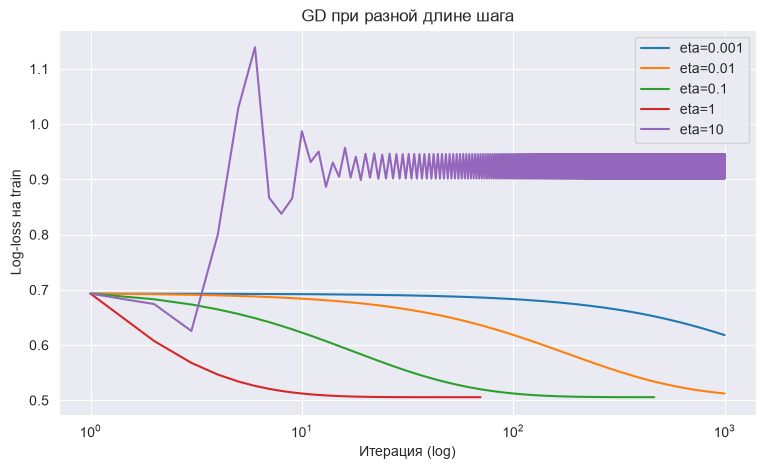

,eta,n_iter,final_loss
0,0.001,1000,0.618141
1,0.010,1000,0.512451
2,0.100,465,0.505762
3,1.000,70,0.505757
4,10.000,1000,0.945807


In [7]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
rows = []
plt.figure(figsize=(9, 5))
for eta in etas:
    m = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    rows.append({'eta': eta, 'n_iter': m.n_iter_, 'final_loss': m.loss_history[-1]})
    plt.plot(np.arange(1, len(m.loss_history) + 1), m.loss_history, label=f'eta={eta}')
plt.xscale('log')
plt.xlabel('Итерация (log)')
plt.ylabel('Log-loss на train')
plt.title('GD при разной длине шага')
plt.legend()
plt.show()

pd.DataFrame(rows)

**Выводы.** Чем больше шаг, тем быстрее сходимость: при `eta=1e-3` и `1e-2` за 1000 итераций спуск не дошёл до минимума (loss 0.618 и 0.512), при `eta=0.1` сошёлся за 465 итераций, при `eta=1` — всего за 70, к тому же минимальному loss ≈ 0.5058. Но слишком большой шаг вредит: при `eta=10` спуск «перепрыгивает» минимум, loss скачет и остаётся высоким (0.95), сходимости нет. Плохо ведут себя и слишком маленькие шаги (очень медленно), и слишком большие (расходится/колеблется).

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk = LogisticRegression().fit(X_train, y_train)

res = []
for name, m in [('My GD', gd), ('My SGD', sgd), ('sklearn', sk)]:
    res.append({
        'model': name,
        'accuracy': metrics.accuracy_score(y_test, m.predict(X_test)),
        'roc_auc': metrics.roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
    })
display(pd.DataFrame(res).set_index('model'))

# сравнение весов
sk_noreg = LogisticRegression(C=np.inf).fit(X_train, y_train)  # без регуляризации, как у нас
gd_long = LogReg(gd_type='full', eta=1, max_iter=10000, tolerance=1e-6).fit(X_train, y_train)

weights = pd.DataFrame({
    'My GD (default)': gd.w,
    'sklearn (default, C=1)': np.r_[sk.intercept_, sk.coef_.ravel()],
    'My GD (eta=1, сошёлся)': gd_long.w,
    'sklearn (C=inf)': np.r_[sk_noreg.intercept_, sk_noreg.coef_.ravel()],
}, index=['w0 (intercept)'] + [f'w{i}' for i in range(1, X_train.shape[1] + 1)])
print('max |GD(default) - sklearn(default)| =', np.abs(weights.iloc[:, 0] - weights.iloc[:, 1]).max().round(4))
print('max |GD(сошёлся) - sklearn(C=inf)|   =', np.abs(weights.iloc[:, 2] - weights.iloc[:, 3]).max().round(4))
weights.round(4)

,accuracy,roc_auc
model,,
My GD,0.7820,0.838787
My SGD,0.7825,0.838115
sklearn,0.7765,0.838676


max |GD(default) - sklearn(default)| = 0.1813
max |GD(сошёлся) - sklearn(C=inf)|   = 0.0003


,My GD (default),"sklearn (default, C=1)","My GD (eta=1, сошёлся)",sklearn (C=inf)
w0 (intercept),-0.0021,-0.0219,-0.0222,-0.0219
w1,0.0061,0.0027,0.0028,0.0027
w2,0.0070,0.0090,0.0090,0.0090
w3,-0.5472,-0.7227,-0.7232,-0.7232
w4,-0.1445,-0.2623,-0.2628,-0.2626
w5,0.0125,0.0166,0.0165,0.0166
w6,-0.0063,-0.0115,-0.0115,-0.0115
w7,0.0008,0.0056,0.0056,0.0056
w8,0.0391,0.0572,0.0572,0.0572
w9,-0.0024,-0.0012,-0.0012,-0.0012


**Выводы.**
- Метрики почти совпадают: accuracy ≈ 0.78, ROC-AUC ≈ 0.839 у всех трёх моделей. Веса по умолчанию **не** совпадают (разница до 0.18): наш GD с `eta=0.01` ещё не сошёлся, и задачи у моделей разные.
- В `sklearn` по умолчанию включена **L2-регуляризация** с `C=1.0` (к loss добавляется штраф $\frac{1}{2C}\|w\|^2$), поэтому она решает другую задачу оптимизации. Чтобы решить ту же задачу, что и у нас, нужно отключить регуляризацию: `LogisticRegression(C=np.inf)` (в старых версиях `penalty=None`). Тогда веса сошедшегося GD (`eta=1`) и `sklearn` совпадают до ~3·10⁻⁴.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски:', df.isna().sum().sum())
print('Полных дубликатов:', df.duplicated().sum())
print(f'Prevalence train: {y_train.mean():.4f}, test: {y_test.mean():.4f}')

const_acc = metrics.accuracy_score(y_test, np.zeros_like(y_test))
print(f'Accuracy константной модели (всегда 0): {const_acc:.4f}')

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression())
lr_pipe.fit(X_train, y_train)
print(f'Accuracy логистической регрессии: {metrics.accuracy_score(y_test, lr_pipe.predict(X_test)):.4f}')

Пропуски: 0
Полных дубликатов: 1177
Prevalence train: 0.1966, test: 0.1964
Accuracy константной модели (всегда 0): 0.8036
Accuracy логистической регрессии: 0.8200


**Выводы.**
- Пропусков нет, полных дубликатов 1177. Удалять их не нужно: разные вина вполне могут иметь одинаковые лабораторные показатели и одинаковую оценку, это реальные данные, а не ошибка. (Единственный минус — одинаковые строки могут попасть и в train, и в test.)
- Доля класса 1 ≈ 0.197 и в train, и в test. `stratify=y` нужен, чтобы при несбалансированных классах доля хороших вин в обеих выборках была одинаковой, как в исходных данных.
- Константная модель «всегда 0» даёт accuracy 0.804, логистическая регрессия — 0.820, разница всего 1.6 п.п. Accuracy плохо подходит, потому что из-за дисбаланса классов даже бесполезная модель, которая не находит ни одного хорошего вина, получает высокий accuracy. Нас же интересует именно, насколько хорошо модель находит редкий класс 1.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=98, TN=1501, FP=66, FN=285
sklearn confusion_matrix:
 [[1501   66]
 [ 285   98]]
Совпадает: True


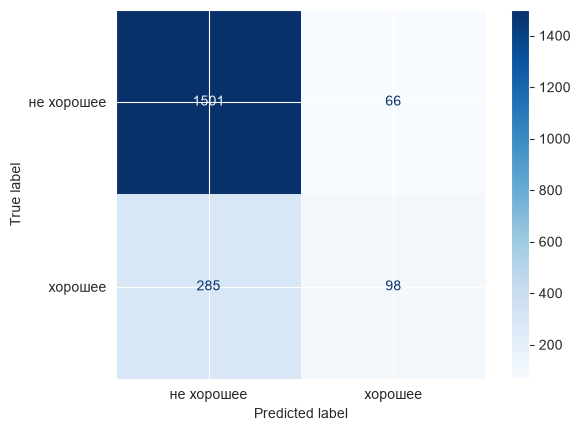

In [12]:
y_pred = lr_pipe.predict(X_test)
yt = np.asarray(y_test)

TP = int(np.sum((y_pred == 1) & (yt == 1)))
TN = int(np.sum((y_pred == 0) & (yt == 0)))
FP = int(np.sum((y_pred == 1) & (yt == 0)))
FN = int(np.sum((y_pred == 0) & (yt == 1)))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')

cm = metrics.confusion_matrix(y_test, y_pred)
print('sklearn confusion_matrix:\n', cm)
print('Совпадает:', np.array_equal(cm, np.array([[TN, FP], [FN, TP]])))

metrics.ConfusionMatrixDisplay(cm, display_labels=['не хорошее', 'хорошее']).plot(cmap='Blues')
plt.show()

**Выводы.** TP=98, TN=1501, FP=66, FN=285, с `sklearn` всё совпало.
- **FP** — посредственное вино модель назвала хорошим и положила в подборку: клиент разочаруется.
- **FN** — хорошее вино модель не заметила и не включила в подборку: подборка беднее.

Чаще встречается FN (285 против 66): при пороге 0.5 модель очень «осторожная» и пропускает большинство хороших вин.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def f_beta(p, r, beta):
    return (1 + beta**2) * p * r / (beta**2 * p + r)

manual = {'precision': precision, 'recall': recall,
          'F1': f_beta(precision, recall, 1),
          'F0.5': f_beta(precision, recall, 0.5),
          'F2': f_beta(precision, recall, 2)}
sk_vals = {'precision': metrics.precision_score(y_test, y_pred),
           'recall': metrics.recall_score(y_test, y_pred),
           'F1': metrics.fbeta_score(y_test, y_pred, beta=1),
           'F0.5': metrics.fbeta_score(y_test, y_pred, beta=0.5),
           'F2': metrics.fbeta_score(y_test, y_pred, beta=2)}
pd.DataFrame({'вручную': manual, 'sklearn': sk_vals}).round(4)

,вручную,sklearn
precision,0.5976,0.5976
recall,0.2559,0.2559
F1,0.3583,0.3583
F0.5,0.4716,0.4716
F2,0.2889,0.2889


**Выводы.** Ручные значения совпали со `sklearn`: precision = 0.598, recall = 0.256, F1 = 0.358, F0.5 = 0.472, F2 = 0.289.
- В $F_{0.5}$ больше ценится **precision**, в $F_2$ — **recall** (при $\beta > 1$ recall важнее).
- Если подписчики болезненно реагируют на посредственные вина, важнее не допускать FP → выбираем $F_{0.5}$.
- Если сервис — «самая широкая подборка хороших вин», важнее не пропускать хорошие вина (FN) → выбираем $F_2$.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Итераций моего GD: 3765


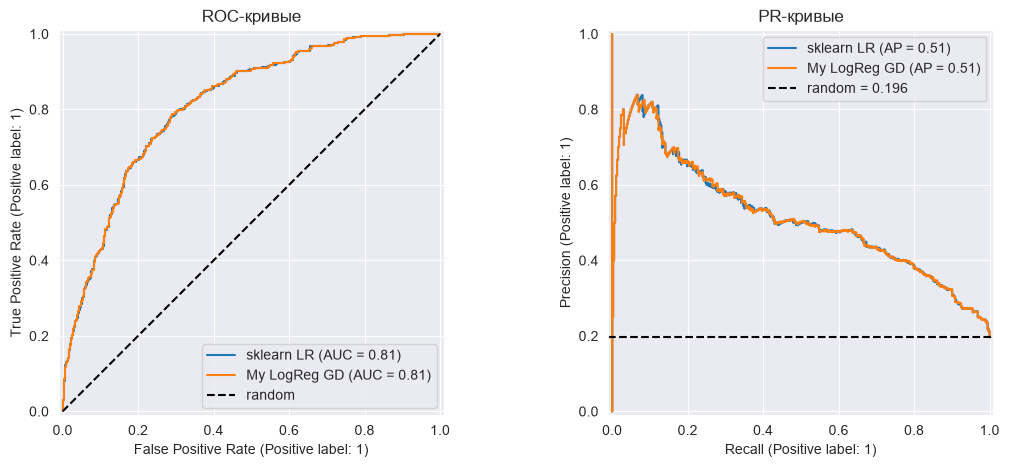

,ROC-AUC,PR-AUC
sklearn LR,0.8135,0.5121
My LogReg GD,0.8135,0.5122


,ROC-AUC
p,0.8135
10p,0.8135
p^3,0.8135
log(p/(1-p)),0.8135
-p,0.1865


ROC-AUC по меткам классов: 0.6069


In [14]:
my_pipe = make_pipeline(StandardScaler(), LogReg(gd_type='full', eta=1, max_iter=10000, tolerance=1e-6))
my_pipe.fit(X_train, y_train)
print('Итераций моего GD:', my_pipe[-1].n_iter_)

scores = {'sklearn LR': lr_pipe.predict_proba(X_test)[:, 1],
          'My LogReg GD': my_pipe.predict_proba(X_test)[:, 1]}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    metrics.RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=ax[1])
ax[0].plot([0, 1], [0, 1], 'k--', label='random')
ax[0].legend()
ax[0].set_title('ROC-кривые')
ax[1].axhline(y_test.mean(), color='k', ls='--', label=f'random = {y_test.mean():.3f}')
ax[1].legend()
ax[1].set_title('PR-кривые')
plt.show()

display(pd.DataFrame({name: {'ROC-AUC': metrics.roc_auc_score(y_test, s),
                             'PR-AUC': metrics.average_precision_score(y_test, s)}
                      for name, s in scores.items()}).T.round(4))

p = scores['sklearn LR']
transforms = {'p': p, '10p': 10 * p, 'p^3': p ** 3,
              'log(p/(1-p))': np.log(p / (1 - p)), '-p': -p}
display(pd.Series({k: metrics.roc_auc_score(y_test, v) for k, v in transforms.items()},
                  name='ROC-AUC').round(4).to_frame())

print('ROC-AUC по меткам классов:', round(metrics.roc_auc_score(y_test, lr_pipe.predict(X_test)), 4))

**Выводы.**
- Модели практически одинаковы: ROC-AUC 0.8135 у обеих, PR-AUC 0.5121 и 0.5122. Это ожидаемо: обе решают одну задачу логистической регрессии (у `sklearn` слабая L2-регуляризация почти ничего не меняет). Ранжирование по ROC-AUC и PR-AUC совпадает (разница на уровне шума).
- ROC-AUC не изменился для $10p$, $p^3$, $\log\frac{p}{1-p}$: это монотонно возрастающие преобразования, они не меняют порядок объектов, а ROC-AUC зависит только от порядка (это вероятность того, что случайный объект класса 1 получит оценку выше случайного объекта класса 0). Для $-p$ порядок переворачивается, поэтому ROC-AUC = 1 − 0.8135 = 0.1865.
- PR-AUC случайной модели равен доле положительного класса ≈ 0.196 (precision случайной модели при любом пороге равен prevalence). Он не равен 0.5, потому что классы несбалансированы; 0.5 — это ROC-AUC случайной модели.
- Если подать метки классов, ROC-кривая строится всего по одной точке (один порог), и ROC-AUC получается заниженным (0.607 вместо 0.81) — теряется информация о ранжировании. Поэтому в `roc_auc_score` подают вероятности.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

t_F1 = 0.27, t_R = 0.24


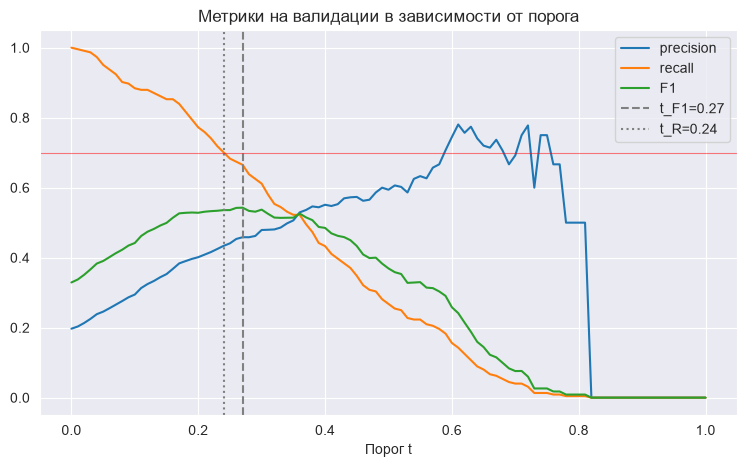

,precision,recall,F1
t=0.5,0.5976,0.2559,0.3583
t_F1=0.27,0.4747,0.6371,0.5440
t_R=0.24,0.4342,0.6893,0.5328


In [15]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)

val_pipe = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
p_val = val_pipe.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0, 1, 101)
curve = pd.DataFrame({
    't': thresholds,
    'precision': [metrics.precision_score(y_val, p_val >= t, zero_division=0) for t in thresholds],
    'recall': [metrics.recall_score(y_val, p_val >= t) for t in thresholds],
    'F1': [metrics.f1_score(y_val, p_val >= t, zero_division=0) for t in thresholds],
})

t_f1 = curve.loc[curve['F1'].idxmax(), 't']
ok = curve[curve['recall'] >= 0.7]
t_r = ok.loc[ok['precision'].idxmax(), 't']
print(f't_F1 = {t_f1:.2f}, t_R = {t_r:.2f}')

plt.figure(figsize=(9, 5))
for col in ['precision', 'recall', 'F1']:
    plt.plot(curve['t'], curve[col], label=col)
plt.axvline(t_f1, color='gray', ls='--', label=f't_F1={t_f1:.2f}')
plt.axvline(t_r, color='gray', ls=':', label=f't_R={t_r:.2f}')
plt.axhline(0.7, color='red', lw=0.8, alpha=0.5)
plt.xlabel('Порог t')
plt.title('Метрики на валидации в зависимости от порога')
plt.legend()
plt.show()

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
p_test = lr_pipe.predict_proba(X_test)[:, 1]
thr_table = pd.DataFrame({
    name: {'precision': metrics.precision_score(y_test, p_test >= t),
           'recall': metrics.recall_score(y_test, p_test >= t),
           'F1': metrics.f1_score(y_test, p_test >= t)}
    for name, t in [('t=0.5', 0.5), (f't_F1={t_f1:.2f}', t_f1), (f't_R={t_r:.2f}', t_r)]
}).T.round(4)
thr_table

**Выводы.** По валидации $t_{F_1} = 0.27$, $t_R = 0.24$. На тесте при $t_R$ recall = 0.689, то есть условие recall ≥ 0.7 **не выполнилось** (чуть-чуть не дотянули). Порог подобран на конкретной небольшой валидационной выборке; на новых данных распределение оценок немного другое (случайность выборки + модель переобучена на всём train), поэтому recall «гуляет» в обе стороны, гарантий нет. Чтобы надёжнее выполнить условие, порог берут с запасом или подбирают по кросс-валидации.

Для сценария я бы выбрала $t_{F_1} = 0.27$: он даёт лучший баланс между «не разочаровать клиента» и «не обеднить подборку» (F1 = 0.544 против 0.358 при пороге 0.5). Порог 0.5 не подходит — он пропускает ~74% хороших вин.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def eval_model(model, name, threshold=0.5, X=X_test, y=y_test):
    """Строка таблицы метрик на тестовой выборке."""
    s = model.predict_proba(X)[:, 1]
    pred = (s >= threshold).astype(int)
    return pd.Series({
        'accuracy': metrics.accuracy_score(y, pred),
        'precision': metrics.precision_score(y, pred, zero_division=0),
        'recall': metrics.recall_score(y, pred),
        'F1': metrics.f1_score(y, pred),
        'ROC-AUC': metrics.roc_auc_score(y, s),
        'PR-AUC': metrics.average_precision_score(y, s),
    }, name=name)

lr_none = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None)).fit(X_train, y_train)
lr_bal = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)

results = pd.DataFrame([eval_model(lr_none, 'LR (без весов)'),
                        eval_model(lr_bal, 'LR balanced')])
display(results.round(4))

# веса по формуле n_samples / (n_classes * np.bincount(y))
n, counts = len(y_train), np.bincount(y_train)
w_bal = n / (2 * counts)
print(f'Число объектов: класс 0 = {counts[0]}, класс 1 = {counts[1]}')
print(f'Веса: класс 0 = {w_bal[0]:.4f}, класс 1 = {w_bal[1]:.4f}')

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR (без весов),0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LR balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005


Число объектов: класс 0 = 3653, класс 1 = 894
Веса: класс 0 = 0.6224, класс 1 = 2.5431


**Выводы.**
1. По формуле `n_samples / (n_classes * np.bincount(y))`: класс 0 получает вес 4547/(2·3653) ≈ **0.62**, класс 1 — 4547/(2·894) ≈ **2.54**. То есть ошибка на хорошем вине стоит примерно в 4 раза дороже.
2. Сильно изменились метрики, зависящие от порога: recall вырос с 0.26 до 0.75, F1 с 0.36 до 0.52, а precision (0.60 → 0.40) и accuracy (0.82 → 0.73) упали. ROC-AUC и PR-AUC почти не изменились (0.81 и 0.50): веса классов в основном сдвигают вероятности в сторону класса 1, а порядок объектов (ранжирование), от которого зависят AUC, почти тот же.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as imb_make_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss-2': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
}

resampled_models = {}
for name, sampler in samplers.items():
    pipe = imb_make_pipeline(StandardScaler(), sampler, LogisticRegression())
    pipe.fit(X_train, y_train)
    resampled_models[name] = pipe
    # размеры классов после ресемплинга (на масштабированном train, как внутри пайплайна)
    _, y_res = sampler.fit_resample(StandardScaler().fit_transform(X_train), y_train)
    print(f'{name:20s} размеры классов после ресемплинга: {np.bincount(y_res)}')
    results = pd.concat([results, eval_model(pipe, name).to_frame().T])

display(results.round(4))

# порядок шагов: ресемплинг до масштабирования
print('Порядок шагов: scaler -> sampler vs sampler -> scaler')
order = []
for name in ['NearMiss-2', 'RandomUnderSampler']:
    sampler = samplers[name]
    a = imb_make_pipeline(StandardScaler(), sampler, LogisticRegression()).fit(X_train, y_train)
    b = imb_make_pipeline(sampler, StandardScaler(), LogisticRegression()).fit(X_train, y_train)
    order += [eval_model(a, f'{name}: scaler -> sampler'), eval_model(b, f'{name}: sampler -> scaler')]
pd.DataFrame(order).round(4)

RandomUnderSampler   размеры классов после ресемплинга: [894 894]


NearMiss-2           размеры классов после ресемплинга: [894 894]
RandomOverSampler    размеры классов после ресемплинга: [3653 3653]
SMOTE                размеры классов после ресемплинга: [3653 3653]


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
LR (без весов),0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LR balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss-2,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


Порядок шагов: scaler -> sampler vs sampler -> scaler


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
NearMiss-2: scaler -> sampler,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
NearMiss-2: sampler -> scaler,0.6810,0.3512,0.7363,0.4755,0.7550,0.3934
RandomUnderSampler: scaler -> sampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
RandomUnderSampler: sampler -> scaler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5005


**Выводы.**
- `make_pipeline` из `imblearn` умеет работать с сэмплерами: ресемплинг выполняется **только при `fit`** (на обучающей выборке). При `predict` шаг ресемплинга пропускается, и тестовая выборка проходит только через масштабирование и модель без изменений. Пайплайн `sklearn` вообще не умеет вызывать `fit_resample`.
- Если сбалансировать весь датасет до разбиения, в тест попадут синтетические/продублированные объекты (утечка данных), а распределение классов в тесте будет не таким, как в реальности. Метрики получатся завышенными и не будут отражать реальное качество.
- Лучший по PR-AUC — SMOTE (0.504), хотя все методы, кроме NearMiss, почти одинаковы и сопоставимы с `balanced`. Худший — NearMiss-2 (0.400): он оставляет только те объекты класса 0, которые ближе всего к объектам класса 1, то есть выкидывает большую и «типичную» часть данных, и модель учится на искажённом распределении.
- Порядок важен для **NearMiss и SMOTE**: они используют расстояния (ближайших соседей), а расстояния зависят от масштаба признаков (например, `total_sulfur_dioxide` в сотнях, а `density` около 1). Для **RandomUnderSampler и RandomOverSampler** порядок почти не важен: они выбирают объекты случайно, без расстояний. Проверка подтверждает: у RandomUnderSampler метрики при перестановке шагов совпали, а у NearMiss-2 заметно изменились (ROC-AUC 0.740 → 0.755, recall 0.85 → 0.74).

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

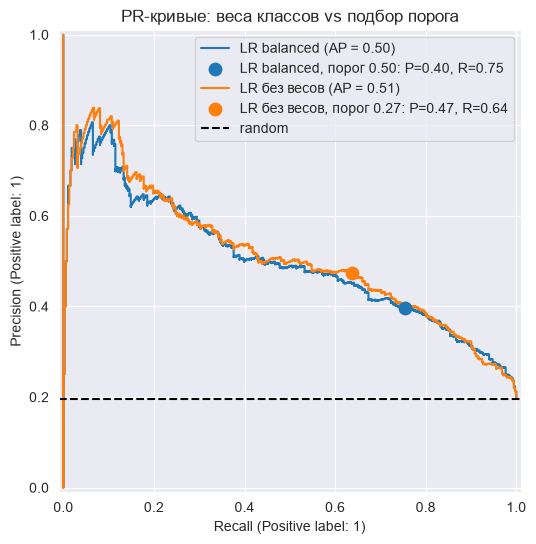

Корреляция Спирмена между оценками двух моделей: 0.9953


In [18]:
p_bal = lr_bal.predict_proba(X_test)[:, 1]
p_none = lr_none.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
for name, s, t in [('LR balanced', p_bal, 0.5), ('LR без весов', p_none, t_f1)]:
    metrics.PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=ax)
    pr, rc = metrics.precision_score(y_test, s >= t), metrics.recall_score(y_test, s >= t)
    ax.scatter(rc, pr, s=80, zorder=5, label=f'{name}, порог {t:.2f}: P={pr:.2f}, R={rc:.2f}')
ax.axhline(y_test.mean(), color='k', ls='--', label='random')
ax.legend()
ax.set_title('PR-кривые: веса классов vs подбор порога')
plt.show()

print('Корреляция Спирмена между оценками двух моделей:',
      round(pd.Series(p_bal).corr(pd.Series(p_none), method='spearman'), 4))

results = pd.concat([results, eval_model(lr_none, f'LR без весов, t_F1={t_f1:.2f}', threshold=t_f1).to_frame().T,
                     eval_model(lr_none, f'LR без весов, t_R={t_r:.2f}', threshold=t_r).to_frame().T])

**Выводы.** PR-кривые двух моделей почти совпадают (PR-AUC 0.500 и 0.512, корреляция Спирмена оценок 0.995 — объекты упорядочены почти одинаково). Точки при выбранных порогах тоже близки: balanced@0.5 даёт P ≈ 0.40, R ≈ 0.75, модель без весов при $t_{F_1}=0.27$ — P ≈ 0.47, R ≈ 0.64, то есть это просто разные точки на почти одной и той же кривой. Значит, да: для логистической регрессии взвешивание классов в основном «сдвигает порог», того же эффекта можно добиться выбором порога у обычной модели.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
my_row = eval_model(my_pipe, 'My LogReg GD')
final_table = pd.concat([results, my_row.to_frame().T])
final_table.round(4).sort_values('PR-AUC', ascending=False)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
My LogReg GD,0.8215,0.6036,0.2663,0.3696,0.8135,0.5122
LR (без весов),0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
"LR без весов, t_F1=0.27",0.7903,0.4747,0.6371,0.5440,0.8135,0.5121
"LR без весов, t_R=0.24",0.7626,0.4342,0.6893,0.5328,0.8135,0.5121
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
LR balanced,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
NearMiss-2,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001


**Выводы.** По ранжированию (ROC-AUC, PR-AUC) все модели, кроме NearMiss-2, почти одинаковы: лучшие — обычная логистическая регрессия (и наш GD), PR-AUC ≈ 0.512. Различия по precision/recall/F1 определяются в основном порогом.

Сервису я бы предложила **обычную логистическую регрессию (`StandardScaler` + `LogisticRegression`) с порогом $t_{F_1} = 0.27$**, подобранным на валидации: у неё лучший F1 на тесте (0.544), precision 0.47 и recall 0.64 — в подборку попадает почти 2/3 хороших вин, и примерно каждое второе вино в подборке действительно хорошее. Модель простая, без ресемплинга, и порог можно двигать под требования сервиса (выше — подборка «строже», ниже — шире). Если для сервиса жёстко важно recall ≥ 0.7, порог стоит брать с запасом ниже $t_R$ (подбирая его по кросс-валидации, а не по тесту).

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)  # ваш итоговый пайплайн, обученный на X_train
final_threshold = t_f1  # выбранный порог

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Ссылка на GitHub-репозиторий:** https://github.com/tatevikkkkkkk/hw3

**Приложение на Streamlit Community Cloud:** https://ypn5nbx7m9czerloduu3v6.streamlit.app/

**Опишите общие мысли о работе.** 🍷

Главный вывод для меня: для логистической регрессии почти все способы борьбы с дисбалансом (веса классов, over/undersampling) дают примерно одну и ту же PR-кривую, а реальную разницу делает выбор порога под задачу. И accuracy на несбалансированных данных почти ничего не говорит о качестве.